# Brandt egg collections over time

Run all cells to count the **eggs** in records whose `Collector` field contains “Brandt” (case insensitive). Each record contributes its `Individual Count`, rather than counting one record as one egg. The chart shows a separate total for **each calendar day**, including zeroes on days without matching records. Every year gets a labeled tick; months and days remain in the underlying plotted dates. The PNG is saved next to the input CSV.

The CSV is expected at the `G:` drive path below. If you move it, edit `CSV_PATH` in the first code cell. In this export, `year`, `month`, and `date collected m/d/y` can hold the year, numeric month, and **day of month** separately (for example, `1904`, `5`, `4`). The notebook also accepts a complete date in the last field, and can use `MonthCollected` when numeric `month` is empty. Records without an exact valid date or a positive whole-number egg count are reported and excluded; they are never assigned a guessed day.


In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import StrMethodFormatter

CSV_PATH = Path(r"G:\My Drive\Egg Slip Scanning\EggSlipReorganizationProject_FULL.xlsx - Full List.csv")
OUTPUT_PATH = CSV_PATH.with_name("Brandt_eggs_collected_by_day.png")

if not CSV_PATH.is_file():
    raise FileNotFoundError(f"CSV not found: {CSV_PATH}\nEdit CSV_PATH above if the file has moved.")


In [2]:
# Read only the fields needed for this graph; keep text intact until it is validated.
columns = ["Collector", "Individual Count", "year", "month", "date collected m/d/y", "MonthCollected"]
df = pd.read_csv(CSV_PATH, usecols=columns, dtype="string", encoding="utf-8-sig")

brandt = df.loc[df["Collector"].str.contains("Brandt", case=False, na=False)].copy()
if brandt.empty:
    raise ValueError("No rows have 'Brandt' in Collector. Check the CSV and collector spelling.")

# Here 'date collected m/d/y' usually contains only the day of the month.
# Build an exact date from the three separate columns, with MonthCollected as
# a month-name fallback. A complete date in the day field also works.
numeric_year = pd.to_numeric(brandt["year"].str.strip(), errors="coerce")
numeric_year = numeric_year.where(numeric_year.eq(numeric_year.round()))
numeric_month = pd.to_numeric(brandt["month"].str.strip(), errors="coerce")
numeric_month = numeric_month.where(numeric_month.eq(numeric_month.round()) & numeric_month.between(1, 12))
month_names = dict(zip(
    ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"],
    range(1, 13),
))
named_month = brandt["MonthCollected"].str.strip().str[:3].str.lower().map(month_names)
numeric_month = numeric_month.fillna(named_month)

day_text = brandt["date collected m/d/y"].str.strip()
day_only = day_text.where(day_text.str.fullmatch(r"[0-9]{1,2}(?:\.0+)?").fillna(False))
numeric_day = pd.to_numeric(day_only, errors="coerce")

parts = pd.DataFrame({
    "year": numeric_year.astype("Int64").astype("string"),
    "month": numeric_month.astype("Int64").astype("string").str.zfill(2),
    "day": numeric_day.astype("Int64").astype("string").str.zfill(2),
}, index=brandt.index)
split_date = pd.to_datetime(
    parts["year"] + "-" + parts["month"] + "-" + parts["day"],
    format="%Y-%m-%d", errors="coerce",
)
full_date = pd.to_datetime(day_text, format="%m/%d/%Y", errors="coerce")
full_date = full_date.fillna(pd.to_datetime(day_text, format="%Y-%m-%d", errors="coerce"))
brandt["collection_date"] = full_date.fillna(split_date)
brandt["egg_count"] = pd.to_numeric(
    brandt["Individual Count"].str.replace(",", "", regex=False).str.strip(),
    errors="coerce",
)

valid_date = brandt["collection_date"].notna() & brandt["collection_date"].dt.year.between(1700, pd.Timestamp.today().year)
valid_count = (
    brandt["egg_count"].gt(0) & brandt["egg_count"].eq(brandt["egg_count"].round())
).fillna(False)
usable = brandt.loc[valid_date & valid_count, ["collection_date", "egg_count"]].copy()
if usable.empty:
    raise ValueError("Brandt records were found, but none has both an exact valid date and a positive whole-number Individual Count.")

usable["egg_count"] = usable["egg_count"].astype(int)

print(f"Brandt records found: {len(brandt):,}")
print(f"Records excluded for missing/invalid exact date: {(~valid_date).sum():,}")
print(f"Records excluded for missing/invalid egg count: {(~valid_count).sum():,}")
print(f"Records plotted: {len(usable):,}")
print(f"Eggs plotted: {usable['egg_count'].sum():,}")


Brandt records found: 3,338
Records excluded for missing/invalid exact date: 47
Records excluded for missing/invalid egg count: 0
Records plotted: 3,291
Eggs plotted: 13,095


Saved graph: G:\My Drive\Egg Slip Scanning\Brandt_eggs_collected_by_day.png


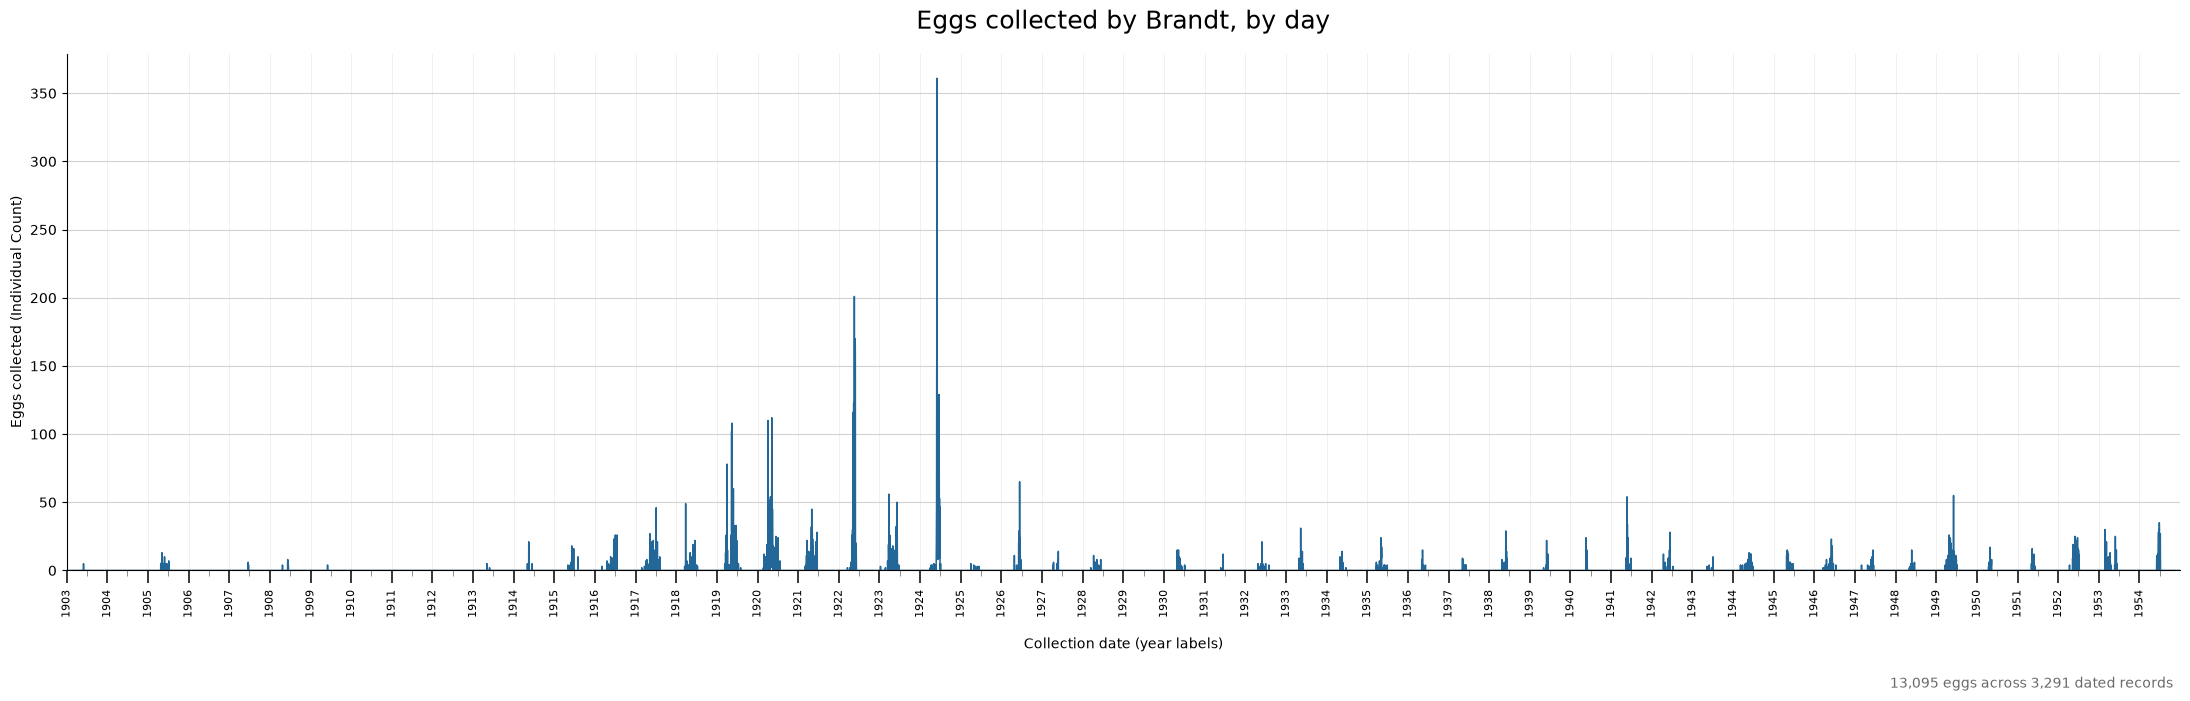

In [3]:
# One value per actual calendar day, including zeroes between collection dates.
daily = usable.groupby("collection_date")["egg_count"].sum().sort_index()
first_year, last_year = daily.index.min().year, daily.index.max().year
calendar_days = pd.date_range(f"{first_year}-01-01", f"{last_year}-12-31", freq="D")
daily = daily.reindex(calendar_days, fill_value=0)

fig, ax = plt.subplots(figsize=(22, 7))
ax.plot(daily.index, daily.values, color="#236798", linewidth=1.1)
ax.set_title("Eggs collected by Brandt, by day", fontsize=18, pad=18)
ax.set_xlabel("Collection date (year labels)", labelpad=14)
ax.set_ylabel("Eggs collected (Individual Count)")
ax.set_ylim(bottom=0)
ax.set_xlim(calendar_days.min(), calendar_days.max())
ax.xaxis.set_major_locator(mdates.YearLocator(1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=7))  # Unlabeled midsummer mark.
ax.tick_params(axis="x", which="major", length=9, width=1.1, labelrotation=90, labelsize=8, pad=5)
ax.tick_params(axis="x", which="minor", length=4, width=0.7, color="0.55")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", color="0.82", linewidth=0.8)
ax.grid(axis="x", which="major", color="0.88", linewidth=0.55, alpha=0.6)
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.99, 0.01, f"{daily.sum():,} eggs across {len(usable):,} dated records", ha="right", fontsize=10, color="dimgray")

fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(OUTPUT_PATH, dpi=200, bbox_inches="tight")
print(f"Saved graph: {OUTPUT_PATH}")
plt.show()
